# 06 — Tableau comparatif final et conclusions

**Responsable : toute l'équipe (consolidation : Membre 1)** · Entrées : `reports/results/*.json` produits par les notebooks 01 à 05 et modèles dans `models/`.

Tous les chiffres ci-dessous sont mesurés sur le **même jeu de test** (20 % des données dédupliquées, jamais utilisé pour choisir un modèle, un seuil ou un hyper-paramètre).

In [1]:
import sys, warnings, joblib
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import ml_utils as U
from sklearn.metrics import confusion_matrix
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format); pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)
R = U.load_results(); print("Résultats disponibles :", list(R))
prep = R["prep"]; print(f"Données : {prep['n_rows_raw']:,} lignes brutes -> {prep['n_rows_clean']:,} après déduplication ; split {prep['train']:,}/{prep['valid']:,}/{prep['test']:,} ; {prep['n_features']} variables")

Résultats disponibles : ['02_rf_anomaly', '03_svm_anomaly', '04_rf_regressor', '05_xgb_regressor', 'prep']
Données : 211,043 lignes brutes -> 183,554 après déduplication ; split 110,132/36,711/36,711 ; 33 variables


## 1. Détection d'anomalies (cible binaire `label`) — test

In [2]:
A = {"Random Forest": R["02_rf_anomaly"], "SVM": R["03_svm_anomaly"]}
rows = []
for name, r in A.items():
    for mode, key in [("seuil calibré (valid)", "test"), ("seuil par défaut", "test_default_threshold")]:
        rows.append({"modèle": r["model"], "décision": mode, "équilibrage": r["balancing"], **{k: r[key][k] for k in ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "mcc", "fpr", "fnr", "roc_auc", "pr_auc"]}, "fit_s": r["fit_time_s"]})
tab_a = pd.DataFrame(rows); display(tab_a.round(4))

,modèle,décision,équilibrage,accuracy,balanced_accuracy,precision,recall,f1,mcc,fpr,fnr,roc_auc,pr_auc,fit_s
0,Random Forest,seuil calibré (valid),Sur-échantillonnage,0.9984,0.9976,0.9988,0.9992,0.9990,0.9956,0.0039,0.0008,1.0000,1.0000,99.6105
1,Random Forest,seuil par défaut,Sur-échantillonnage,0.9984,0.9977,0.9989,0.9991,0.9990,0.9956,0.0038,0.0009,1.0000,1.0000,99.6105
2,SVM (SVM RBF (20k lignes)),seuil calibré (valid),Aucun,0.9946,0.9920,0.9962,0.9968,0.9965,0.9848,0.0128,0.0032,0.9992,0.9997,1.1259
3,SVM (SVM RBF (20k lignes)),seuil par défaut,Aucun,0.9946,0.9920,0.9962,0.9968,0.9965,0.9846,0.0128,0.0032,0.9992,0.9997,1.1259


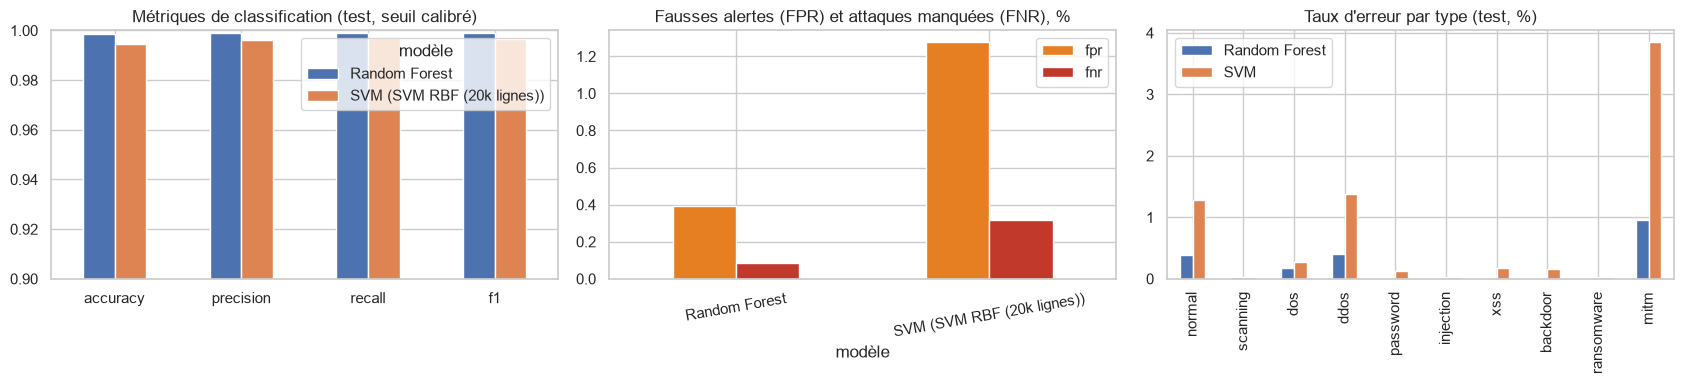

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
m = tab_a[tab_a["décision"] == "seuil calibré (valid)"].set_index("modèle")
m[["accuracy", "precision", "recall", "f1"]].T.plot(kind="bar", ax=axes[0]); axes[0].set_title("Métriques de classification (test, seuil calibré)"); axes[0].set_ylim(.9, 1); axes[0].tick_params(axis="x", rotation=0)
m[["fpr", "fnr"]].mul(100).plot(kind="bar", ax=axes[1], color=["#e67e22", "#c0392b"]); axes[1].set_title("Fausses alertes (FPR) et attaques manquées (FNR), %"); axes[1].tick_params(axis="x", rotation=10)
pd.DataFrame({k: v["error_by_type"] for k, v in A.items()}).loc[U.TYPE_ORDER].mul(100).plot(kind="bar", ax=axes[2]); axes[2].set_title("Taux d'erreur par type (test, %)")
plt.tight_layout(); U.savefig(fig, "06_anomaly_comparison"); plt.show()

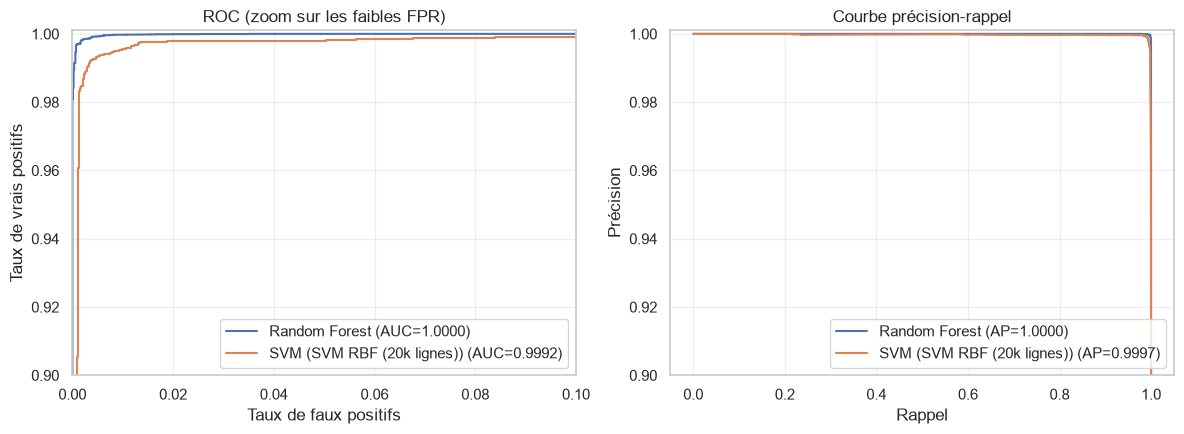

In [4]:
rf, svm = joblib.load(U.MODEL_DIR / "rf_anomaly.joblib"), joblib.load(U.MODEL_DIR / "svm_anomaly.joblib")
Xte, yte_df = U.load_split("test"); yb = yte_df["label"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
U.plot_roc_pr(yb, rf.predict_proba(Xte)[:, 1], "Random Forest", axes=axes); U.plot_roc_pr(yb, svm.decision_function(Xte), R["03_svm_anomaly"]["model"], axes=axes)
axes[0].set_xlim(0, .1); axes[0].set_ylim(.9, 1.001); axes[0].set_title("ROC (zoom sur les faibles FPR)"); axes[1].set_ylim(.9, 1.001)
plt.tight_layout(); U.savefig(fig, "06_anomaly_roc_pr"); plt.show()

## 2. Prédiction du type (régression ordinale) — test

In [5]:
T = {"Random Forest Regressor": R["04_rf_regressor"], "XGBoost Regressor": R["05_xgb_regressor"]}
rows = []
for name, r in T.items():
    rows.append({"modèle": name, "pondération": r["weighting"], "MAE": r["test"]["mae"], "RMSE": r["test"]["rmse"], "R²": r["test"]["r2"],
                 "accuracy (arrondi)": r["test_rounded"]["accuracy"], "F1 macro (arrondi)": r["test_rounded"]["f1_macro"],
                 "accuracy (seuils opt.)": r["test"]["accuracy"], "F1 macro (seuils opt.)": r["test"]["f1_macro"], "balanced acc (seuils opt.)": r["test"]["balanced_accuracy"],
                 "±1 classe": r["test"]["within_1_class"], "fit_s": r["fit_time_s"]})
tab_t = pd.DataFrame(rows).set_index("modèle"); display(tab_t.round(4))

,pondération,MAE,RMSE,R²,accuracy (arrondi),F1 macro (arrondi),accuracy (seuils opt.),F1 macro (seuils opt.),balanced acc (seuils opt.),±1 classe,fit_s
modèle,,,,,,,,,,,
Random Forest Regressor,Aucun,0.0478,0.3485,0.9836,0.9774,0.9140,0.9800,0.9335,0.9195,0.9903,40.9515
XGBoost Regressor,Aucun,0.0738,0.3559,0.9829,0.9718,0.9009,0.9761,0.9225,0.9099,0.9887,15.8825


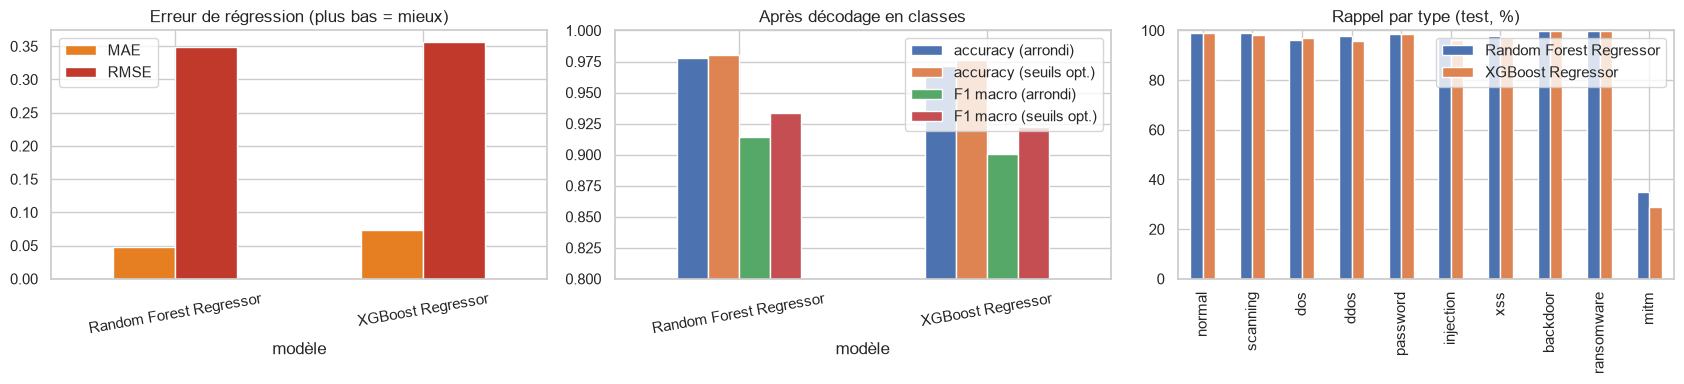

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
tab_t[["MAE", "RMSE"]].plot(kind="bar", ax=axes[0], color=["#e67e22", "#c0392b"]); axes[0].set_title("Erreur de régression (plus bas = mieux)"); axes[0].tick_params(axis="x", rotation=10)
tab_t[["accuracy (arrondi)", "accuracy (seuils opt.)", "F1 macro (arrondi)", "F1 macro (seuils opt.)"]].plot(kind="bar", ax=axes[1]); axes[1].set_ylim(.8, 1); axes[1].set_title("Après décodage en classes"); axes[1].tick_params(axis="x", rotation=10)
pd.DataFrame({k: v["recall_by_type"] for k, v in T.items()}).loc[U.TYPE_ORDER].mul(100).plot(kind="bar", ax=axes[2]); axes[2].set_title("Rappel par type (test, %)"); axes[2].set_ylim(0, 100)
plt.tight_layout(); U.savefig(fig, "06_type_comparison"); plt.show()

## 3. Tableau comparatif unique des 4 modèles

In [7]:
rows = []
for name, r in A.items():
    t = r["test"]; rows.append({"tâche": "Détection d'anomalies (binaire)", "modèle": r["model"], "équilibrage / poids": r["balancing"], "accuracy": t["accuracy"], "precision": t["precision"], "recall": t["recall"], "f1": t["f1"],
                                "roc_auc": t["roc_auc"], "pr_auc": t["pr_auc"], "mcc": t["mcc"], "fpr": t["fpr"], "fnr": t["fnr"], "temps_apprentissage_s": r["fit_time_s"]})
for name, r in T.items():
    t = r["test"]; rows.append({"tâche": "Prédiction du type (régression)", "modèle": name, "équilibrage / poids": r["weighting"], "accuracy": t["accuracy"], "f1": t["f1_macro"], "balanced_accuracy": t["balanced_accuracy"],
                                "mae": t["mae"], "rmse": t["rmse"], "r2": t["r2"], "temps_apprentissage_s": r["fit_time_s"]})
final_tab = pd.DataFrame(rows); final_tab.to_csv(U.REPORT_DIR / "model_comparison.csv", index=False, encoding="utf-8-sig")
display(final_tab.round(4))
(U.REPORT_DIR / "model_comparison.md").write_text(final_tab.round(4).fillna("").to_markdown(index=False) if hasattr(final_tab, "to_markdown") else final_tab.round(4).to_string(), encoding="utf-8")
print("Sauvegardé :", U.REPORT_DIR / "model_comparison.csv")

,tâche,modèle,équilibrage / poids,accuracy,precision,recall,f1,roc_auc,pr_auc,mcc,fpr,fnr,temps_apprentissage_s,balanced_accuracy,mae,rmse,r2
0,Détection d'anomalies (binaire),Random Forest,Sur-échantillonnage,0.9984,0.9988,0.9992,0.9990,1.0000,1.0000,0.9956,0.0039,0.0008,99.6105,NaN,NaN,NaN,NaN
1,Détection d'anomalies (binaire),SVM (SVM RBF (20k lignes)),Aucun,0.9946,0.9962,0.9968,0.9965,0.9992,0.9997,0.9848,0.0128,0.0032,1.1259,NaN,NaN,NaN,NaN
2,Prédiction du type (régression),Random Forest Regressor,Aucun,0.9800,NaN,NaN,0.9335,NaN,NaN,NaN,NaN,NaN,40.9515,0.9195,0.0478,0.3485,0.9836
3,Prédiction du type (régression),XGBoost Regressor,Aucun,0.9761,NaN,NaN,0.9225,NaN,NaN,NaN,NaN,NaN,15.8825,0.9099,0.0738,0.3559,0.9829


Sauvegardé : C:\Users\medamine\Desktop\Desktop\esprit\ml_project_toniot\project\reports\model_comparison.csv


## 4. Comparaison avec l'ancienne version
Deux corrections méthodologiques et plusieurs améliorations ont été appliquées ; leurs effets sont **différents selon le modèle** :
1. **Déduplication avant le split** (≈ 27 000 lignes identiques sur les variables du modèle) : supprime tout recouvrement train/test, donc des scores sans fuite par mémorisation.
2. **Vraies valeurs manquantes** (les `-` de Zeek) et indicateurs `has_*`.
3. **Feature engineering, `log1p` + standardisation, réglage** et SVM RBF.
Le Random Forest, déjà quasi parfait, bouge à peine ; le **SVM** progresse nettement (le `log1p`/la standardisation et le noyau RBF lui profitent surtout).

In [8]:
old = pd.DataFrame({"ancienne version (sans déduplication)": {"RF classifieur — F1": .9987, "SVM linéaire — F1": .9720, "RF régresseur — accuracy arrondie": .9710, "XGBoost régresseur — accuracy arrondie": .9629}})
new = pd.Series({"RF classifieur — F1": A["Random Forest"]["test"]["f1"], "SVM linéaire — F1": A["SVM"]["test"]["f1"],
                 "RF régresseur — accuracy arrondie": T["Random Forest Regressor"]["test_rounded"]["accuracy"], "XGBoost régresseur — accuracy arrondie": T["XGBoost Regressor"]["test_rounded"]["accuracy"]}, name="version corrigée")
display(old.join(new).round(4))

,ancienne version (sans déduplication),version corrigée
RF classifieur — F1,0.9987,0.9990
SVM linéaire — F1,0.9720,0.9965
RF régresseur — accuracy arrondie,0.9710,0.9774
XGBoost régresseur — accuracy arrondie,0.9629,0.9718


## 5. Synthèse et recommandations

In [9]:
best_a = tab_a[tab_a["décision"] == "seuil calibré (valid)"].sort_values(["f1", "pr_auc"], ascending=False).iloc[0]
best_t = tab_t.sort_values(["F1 macro (seuils opt.)", "RMSE"], ascending=[False, True]).iloc[0]
print(f"Détection d'anomalies  -> meilleur modèle : {best_a['modèle']} (F1 = {best_a['f1']:.4f}, PR-AUC = {best_a['pr_auc']:.4f}, FPR = {best_a['fpr']:.2%}, FNR = {best_a['fnr']:.2%})")
print(f"Prédiction du type     -> meilleur modèle : {best_t.name} (F1 macro = {best_t['F1 macro (seuils opt.)']:.4f}, RMSE = {best_t['RMSE']:.3f}, R² = {best_t['R²']:.4f})")
fast = final_tab.sort_values("temps_apprentissage_s").iloc[0]; print(f"Modèle le plus rapide à entraîner : {fast['modèle']} ({fast['temps_apprentissage_s']:.1f}s)")

Détection d'anomalies  -> meilleur modèle : Random Forest (F1 = 0.9990, PR-AUC = 1.0000, FPR = 0.39%, FNR = 0.08%)
Prédiction du type     -> meilleur modèle : Random Forest Regressor (F1 macro = 0.9335, RMSE = 0.349, R² = 0.9836)
Modèle le plus rapide à entraîner : SVM (SVM RBF (20k lignes)) (1.1s)


### Lecture des résultats
- **Détection** : privilégier le modèle au meilleur compromis F1 / PR-AUC ; vérifier **FPR** (fausses alertes à traiter par un analyste) et **FNR** (attaques manquées, plus coûteuses). Le seuil calibré permet d'ajuster ce compromis sans réentraîner.
- **Type** : la régression ordinale donne de bons scores globaux ; la classe rare `mitm` reste la plus difficile (peu d'exemples, trafic DNS proche du normal). Le rappel par type est la mesure à surveiller.
- **SVM vs arbres** : le SVM exige standardisation et ne passe pas à l'échelle sans approximation de noyau ; les arbres sont plus simples à entraîner et à interpréter sur ces données tabulaires mixtes.

### Limites
- Données générées sur un **banc d'essai** (IP fixes, scénarios scriptés) : la généralisation à un autre réseau n'est pas garantie ; les adresses IP ont été exclues pour limiter ce biais.
- La régression sur un type nominal est imposée par le sujet ; un **classifieur multi-classes** serait plus adapté en production.
- Pas de validation temporelle : le split est aléatoire stratifié (les flux d'une même attaque peuvent être corrélés).

### Pistes
Validation par groupes (par scénario/hôte), classifieur multi-classes + calibration par classe, SHAP pour l'explication locale, surveillance de la dérive en production.

### Points faibles constatés (à assumer à l'oral)
- **`mitm`** (0,6 % des lignes) : rappel de seulement ≈ 0,29 (XGBoost) à ≈ 0,35 (Random Forest) pour les régresseurs, alors que la précision est > 0,95. La pondération `sample_weight` n'a pas aidé (le schéma « Aucun » a été retenu en CV). La régression sur un code ordinal est mal adaptée à une classe rare située à l'extrémité de l'échelle.
- **Ordre d'encodage** : l'étude du notebook 04 §1 n'a pas montré que l'ordre documenté soit meilleur qu'un ordre aléatoire ; le choix d'ordre est arbitraire.
- **XGBoost** : l'arrêt anticipé a atteint le plafond de 2000 arbres (learning rate 0,03) sans converger complètement ; un learning rate plus grand ou un plafond plus haut serait à tester.
- **Détection** : l'écart entre RF et SVM est faible en valeur absolue (F1 0,9990 vs 0,9965) mais le SVM a ≈ 3× plus de fausses alertes (FPR 1,28 % vs 0,39 %).